<a href="https://colab.research.google.com/github/eileen795/MSSP-6070/blob/main/exercise_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
from google.colab import userdata
import os
import subprocess

In [39]:
!pip install yfinance
import yfinance as yf

In [40]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.float_format', lambda x: '%.2f' % x)

#Task 1: Read into seperate data frame the following tickers: Apple, Facebook, Google, and Netflix; use Yahoo finance.

In [41]:
# Task 1: Download stock prices for Apple, Facebook (Meta), Google (Alphabet), Netflix
# Use the same 2019-05-31 to 2021-01-30 window as the class example.
tickers = {'Apple': 'AAPL', 'Facebook': 'META', 'Google': 'GOOGL', 'Netflix': 'NFLX'}
stock_data = {}
for company, ticker in tickers.items():
    stock_data[ticker] = yf.Ticker(ticker).history(start=startDate, end=endDate)
    print(f'{company} ({ticker}): {len(stock_data[ticker])} rows')
    display(stock_data[ticker].head())


Apple (AAPL): 421 rows


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2019-05-31 00:00:00-04:00,42.09,42.51,41.79,41.81,108174400,0.00,0.00
2019-06-03 00:00:00-04:00,41.94,42.49,40.66,41.39,161584400,0.00,0.00
2019-06-04 00:00:00-04:00,41.90,42.95,41.68,42.90,123872000,0.00,0.00
2019-06-05 00:00:00-04:00,44.01,44.18,43.26,43.59,119093600,0.00,0.00
2019-06-06 00:00:00-04:00,43.72,44.29,43.50,44.23,90105200,0.00,0.00


Facebook (META): 421 rows


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2019-05-31 00:00:00-04:00,178.57,178.83,175.48,175.79,15226500,0.00,0.00
2019-06-03 00:00:00-04:00,173.34,173.39,159.48,162.59,56059600,0.00,0.00
2019-06-04 00:00:00-04:00,162.16,166.68,159.31,165.91,46044300,0.00,0.00
2019-06-05 00:00:00-04:00,165.89,167.12,163.07,166.57,19758300,0.00,0.00
2019-06-06 00:00:00-04:00,166.70,168.09,165.64,166.73,12446400,0.00,0.00


Google (GOOGL): 421 rows


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2019-05-31 00:00:00-04:00,54.76,55.15,54.65,54.80,31582000,0.00,0.00
2019-06-03 00:00:00-04:00,52.84,52.85,50.87,51.45,96890000,0.00,0.00
2019-06-04 00:00:00-04:00,51.73,52.42,51.31,52.23,60512000,0.00,0.00
2019-06-05 00:00:00-04:00,52.25,52.34,51.16,51.74,46988000,0.00,0.00
2019-06-06 00:00:00-04:00,51.82,52.01,51.29,51.89,29020000,0.00,0.00


Netflix (NFLX): 421 rows


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2019-05-31 00:00:00-04:00,34.72,34.93,34.29,34.33,50234000,0.00,0.00
2019-06-03 00:00:00-04:00,34.36,34.77,33.26,33.66,78496000,0.00,0.00
2019-06-04 00:00:00-04:00,34.50,35.36,34.33,35.34,78916000,0.00,0.00
2019-06-05 00:00:00-04:00,35.44,35.79,34.87,35.57,50201000,0.00,0.00
2019-06-06 00:00:00-04:00,35.48,35.82,35.21,35.71,37100000,0.00,0.00


#Task 2:  Join the individual stock data frames into a single data frame.

In [42]:
# Task 2: Join the individual stock DataFrames into one DataFrame
# Keep the ticker symbol and date as explicit columns.
combined_stocks = pd.concat(
    [df.assign(Ticker=ticker).reset_index() for ticker, df in stock_data.items()],
    ignore_index=True
)
combined_stocks = combined_stocks.sort_values(['Date', 'Ticker']).reset_index(drop=True)
display(combined_stocks.head())
print('Combined shape:', combined_stocks.shape)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
0,2019-05-31 00:00:00-04:00,42.09,42.51,41.79,41.81,108174400,0.00,0.00,AAPL
1,2019-05-31 00:00:00-04:00,54.76,55.15,54.65,54.80,31582000,0.00,0.00,GOOGL
2,2019-05-31 00:00:00-04:00,178.57,178.83,175.48,175.79,15226500,0.00,0.00,META
3,2019-05-31 00:00:00-04:00,34.72,34.93,34.29,34.33,50234000,0.00,0.00,NFLX
4,2019-06-03 00:00:00-04:00,41.94,42.49,40.66,41.39,161584400,0.00,0.00,AAPL


Combined shape: (1684, 9)


# Task 3: Create a visualization of the following financial metrics for each stock:  quickRatio, currentRatio, totalRevenue, debtToEquity, revenuePerShare, returnOnAssets, returnOnEquity, grossProfits


,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits
Ticker,,,,,,,,
AAPL,0.83,1.02,478833999872,84.29,32.66,0.26,1.42,233602007040
META,1.67,1.90,241605001216,42.16,95.19,0.15,0.32,195782000640
GOOGL,2.51,2.79,471097999360,22.19,38.79,0.13,0.44,286698012672
NFLX,0.84,1.07,49734631424,59.86,11.86,0.17,0.53,25207793664


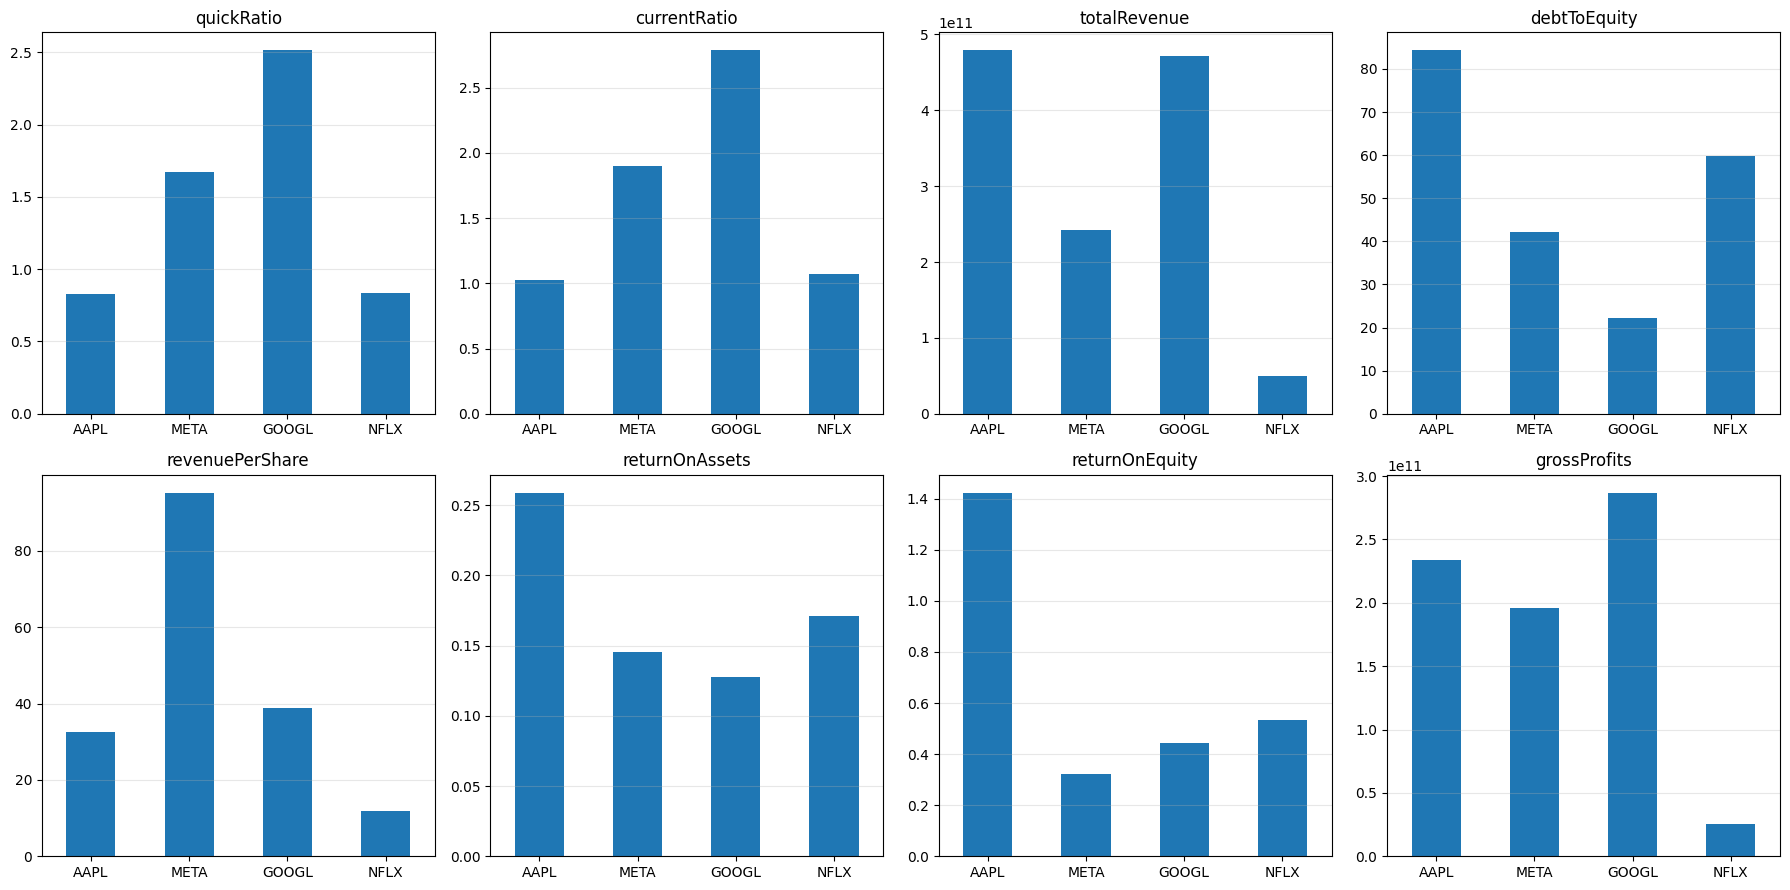

Note: Metrics reflect the latest available company fundamentals, not necessarily 2023.


In [43]:
# Task 3: Visualize eight financial metrics for each stock
metrics = ['quickRatio', 'currentRatio', 'totalRevenue', 'debtToEquity',
           'revenuePerShare', 'returnOnAssets', 'returnOnEquity', 'grossProfits']
# Yahoo Finance uses snake_case keys in some yfinance versions.
metric_aliases = {
    'quickRatio': ['quickRatio', 'quick_ratio'],
    'currentRatio': ['currentRatio', 'current_ratio'],
    'totalRevenue': ['totalRevenue', 'total_revenue'],
    'debtToEquity': ['debtToEquity', 'debt_to_equity'],
    'revenuePerShare': ['revenuePerShare', 'revenue_per_share'],
    'returnOnAssets': ['returnOnAssets', 'return_on_assets'],
    'returnOnEquity': ['returnOnEquity', 'return_on_equity'],
    'grossProfits': ['grossProfits', 'gross_profits']
}
rows = []
for company, ticker in tickers.items():
    info = yf.Ticker(ticker).info
    row = {'Ticker': ticker}
    for metric in metrics:
        row[metric] = next((info[k] for k in metric_aliases[metric]
                            if info.get(k) is not None), np.nan)
    rows.append(row)
financial_metrics = pd.DataFrame(rows).set_index('Ticker')
display(financial_metrics)
# Separate panels: financial metrics have very different scales.
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, metric in zip(axes.flat, metrics):
    financial_metrics[metric].plot(kind='bar', ax=ax, title=metric)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
print('Note: Metrics reflect the latest available company fundamentals, not necessarily 2023.')


#Task 4: Create a single boxplot for the Closing price for each stock.


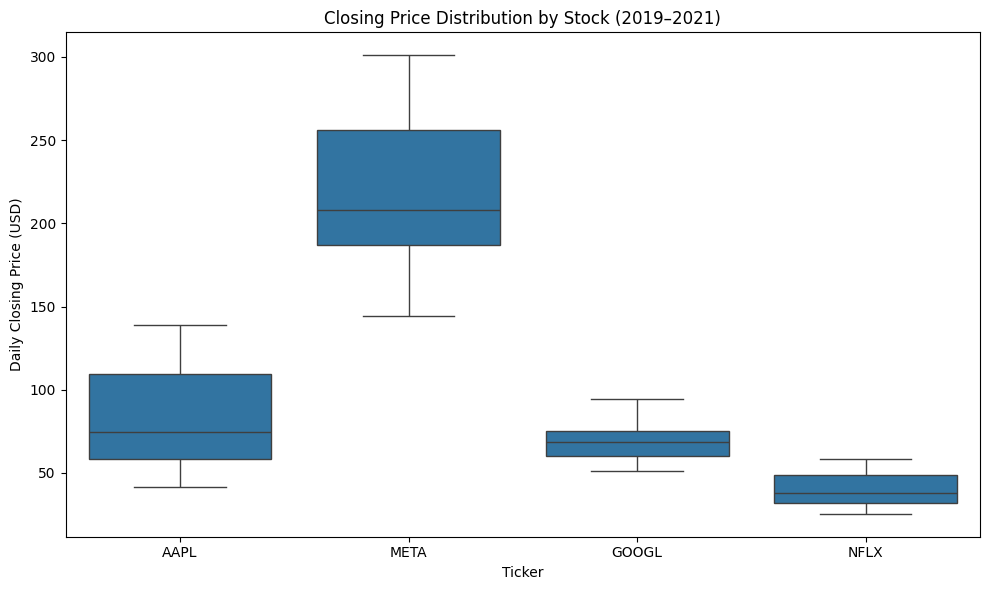

In [44]:
# Task 4: One boxplot comparing closing prices of all four stocks
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_stocks, x='Ticker', y='Close', order=list(tickers.values()))
plt.title('Closing Price Distribution by Stock (2019–2021)')
plt.xlabel('Ticker')
plt.ylabel('Daily Closing Price (USD)')
plt.tight_layout()
plt.show()


# Task 5: Create a daily trading volume visualization for the year 2023 for each stock.


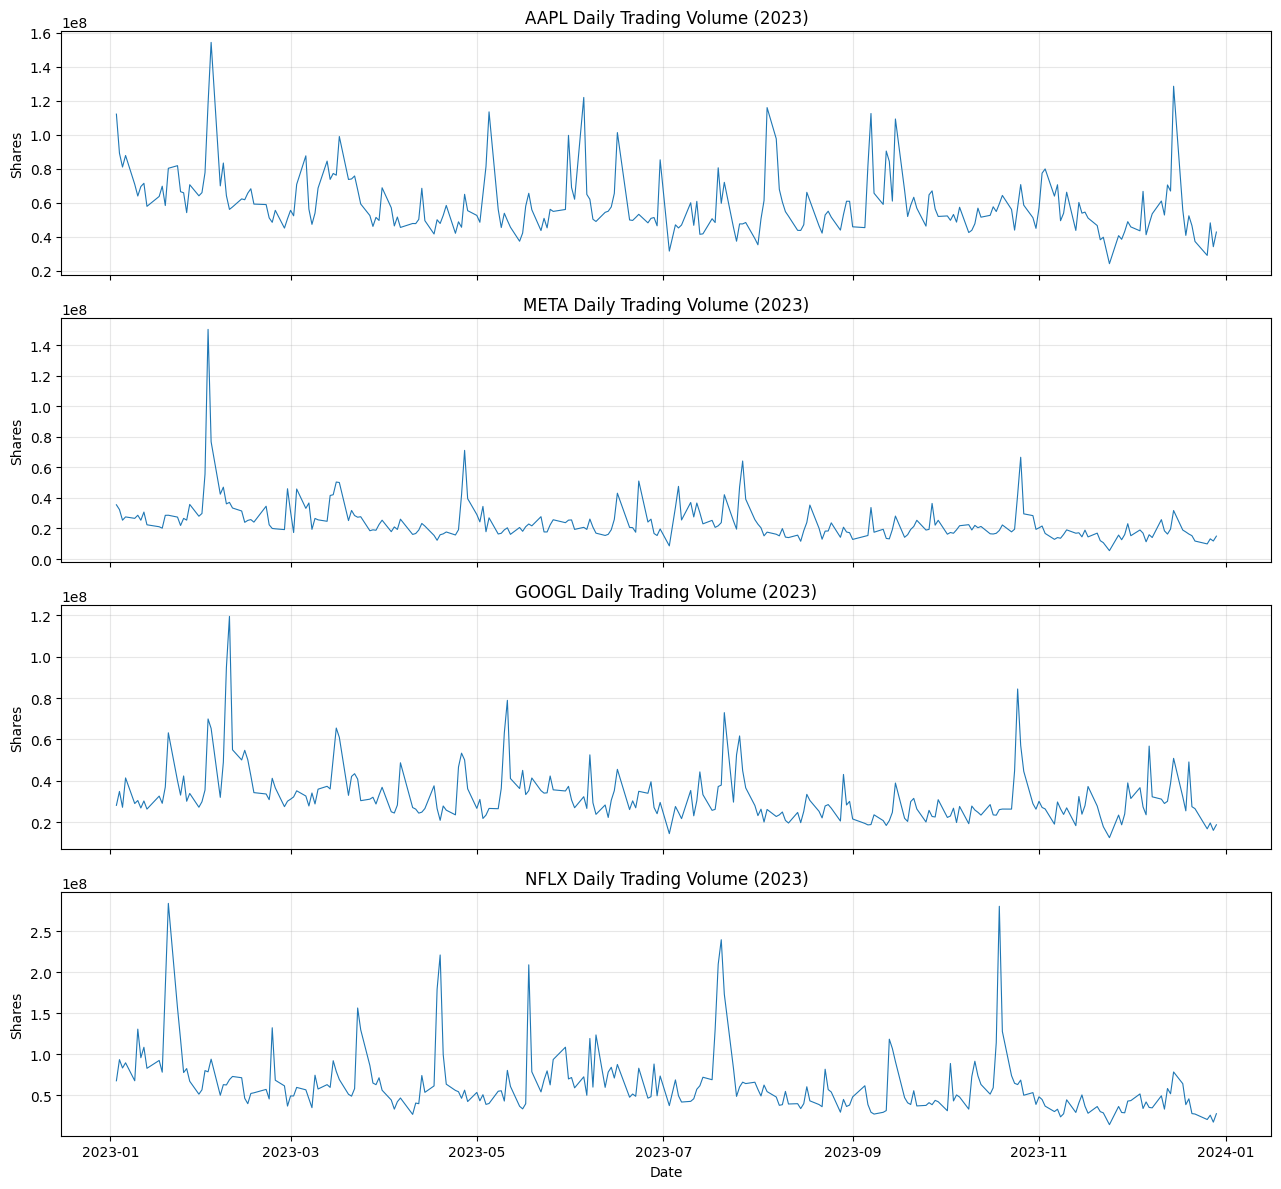

In [45]:
# Task 5: Daily trading volume during 2023 for each stock
volume_2023 = []
for ticker in tickers.values():
    history = yf.Ticker(ticker).history(start='2023-01-01', end='2024-01-01')
    history = history.reset_index()
    history['Ticker'] = ticker
    volume_2023.append(history[['Date', 'Ticker', 'Volume']])
volume_2023 = pd.concat(volume_2023, ignore_index=True)
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
for ax, ticker in zip(axes, tickers.values()):
    subset = volume_2023[volume_2023['Ticker'] == ticker]
    ax.plot(subset['Date'], subset['Volume'], linewidth=0.8)
    ax.set_title(f'{ticker} Daily Trading Volume (2023)')
    ax.set_ylabel('Shares')
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()


#Task 6: Save the combined stock file with the ticker symbols to a CSV file in you Google directory.  Upload the Jupyter Notebook to the assignment in Canvas.

In [46]:
# Task 6: Save the combined stock data as a CSV in Google Drive
# The CSV includes the Ticker column identifying each company.
from pathlib import Path
output_dir = Path('/content/drive/MyDrive') if Path('/content/drive/MyDrive').exists() else Path.cwd()
output_path = output_dir / 'Week13_Combined_Stocks.csv'
combined_stocks.to_csv(output_path, index=False)
print(f'Saved CSV to: {output_path}')
print('Submit this completed .ipynb notebook to Canvas.')


Saved CSV to: /content/drive/MyDrive/Week13_Combined_Stocks.csv
Submit this completed .ipynb notebook to Canvas.
